<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/BAB%205/Latihan%20Praktikum%205_Machine%20Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 5 — Decision Tree: Pre-Pruning dan Cost Complexity Pruning


## Praktikum 5.1 — Persiapan Library

In [1]:
!pip -q install scikit-learn pandas matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Library berhasil diimpor.")

Library berhasil diimpor.


## Praktikum 5.2 — Import Dataset

In [2]:
# Upload CSV jika belum tersedia di folder kerja Google Colab
import os

nama_file = "beast_cancer.csv"
if not os.path.exists(nama_file):
    try:
        from google.colab import files
        uploaded = files.upload()
        nama_file = next(
            (nama for nama in uploaded.keys() if nama.lower().endswith(".csv")),
            None
        )
    except ImportError:
        raise FileNotFoundError("File beast_cancer.csv belum ditemukan.")

if nama_file is None:
    raise FileNotFoundError("Tidak ada file CSV yang diunggah.")

data = pd.read_csv(nama_file)

# Hapus kolom ID dan kolom kosong bawaan file CSV
data = data.drop(columns=["id", "Unnamed: 32"], errors="ignore")

# Diagnosis: M = Malignant (ganas), B = Benign (jinak)
# Target dibuat 1 = Malignant dan 0 = Benign
data["diagnosis"] = data["diagnosis"].map({"M": 1, "B": 0})

X = data.drop(columns=["diagnosis"])
y = data["diagnosis"].astype(int)

print("Sumber data:", nama_file)
print("Ukuran data:", data.shape)
print("Jumlah fitur:", X.shape[1])
print("Distribusi kelas (0=Benign, 1=Malignant):")
print(y.value_counts().sort_index())
display(data.head())

Sumber data: beast_cancer.csv
Ukuran data: (569, 31)
Jumlah fitur: 30
Distribusi kelas (0=Benign, 1=Malignant):
diagnosis
0    357
1    212
Name: count, dtype: int64


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


**Penjelasan dataset:** terdapat 569 baris data dan 30 fitur numerik hasil pengukuran karakteristik sel tumor. Target `diagnosis` diubah menjadi angka: 0 untuk Benign (jinak) dan 1 untuk Malignant (ganas).

## Praktikum 5.3 — Preprocessing (Split Data)

In [3]:
# Pisahkan data training dan testing secara stratified
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing :", X_test.shape[0])
print("\nDistribusi kelas training:")
print(y_train.value_counts().sort_index())
print("\nDistribusi kelas testing:")
print(y_test.value_counts().sort_index())

Jumlah data training: 455
Jumlah data testing : 114

Distribusi kelas training:
diagnosis
0    285
1    170
Name: count, dtype: int64

Distribusi kelas testing:
diagnosis
0    72
1    42
Name: count, dtype: int64


## Praktikum 5.4 — Training Model (dengan dan tanpa Pruning)

In [4]:
# 1. Model tanpa pruning
tree_full = DecisionTreeClassifier(random_state=42)
tree_full.fit(X_train, y_train)

# 2. Model pre-pruning
tree_pre = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)
tree_pre.fit(X_train, y_train)

# 3. Model post-pruning menggunakan Cost Complexity Pruning (CCP)
path = tree_full.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas

# Buang alpha terakhir jika menghasilkan pohon akar tunggal
ccp_alphas = np.unique(ccp_alphas)
if len(ccp_alphas) > 1:
    ccp_alphas = ccp_alphas[:-1]

# Siapkan validation split dari data training untuk memilih alpha
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

akurasi_validasi = []
for alpha in ccp_alphas:
    model = DecisionTreeClassifier(
        random_state=42, ccp_alpha=float(alpha)
    )
    model.fit(X_train_sub, y_train_sub)
    akurasi_validasi.append(accuracy_score(y_val, model.predict(X_val)))

idx_alpha = int(np.argmax(akurasi_validasi))
ccp_alpha_terpilih = float(ccp_alphas[idx_alpha])

tree_ccp = DecisionTreeClassifier(
    random_state=42, ccp_alpha=ccp_alpha_terpilih
)
tree_ccp.fit(X_train, y_train)

print("Jumlah kandidat ccp_alpha:", len(ccp_alphas))
print("ccp_alpha terpilih:", ccp_alpha_terpilih)
print("Akurasi validasi terbaik:", round(akurasi_validasi[idx_alpha], 3))

Jumlah kandidat ccp_alpha: 16
ccp_alpha terpilih: 0.0029304029304029304
Akurasi validasi terbaik: 0.934


**Catatan metodologi:** alpha dipilih menggunakan validation set yang berasal dari data training. Data testing tetap disimpan untuk evaluasi akhir, sehingga tidak digunakan untuk memilih parameter model.

## Praktikum 5.5 — Evaluasi Model

In [5]:
model_list = [
    ("Tanpa Pruning", tree_full),
    ("Pre-Pruning", tree_pre),
    ("Post-Pruning (CCP)", tree_ccp)
]

hasil_evaluasi = []
for nama, model in model_list:
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    hasil_evaluasi.append({
        "Model": nama,
        "Akurasi Train": accuracy_score(y_train, pred_train),
        "Akurasi Test": accuracy_score(y_test, pred_test),
        "Selisih (Gap)": accuracy_score(y_train, pred_train)
                         - accuracy_score(y_test, pred_test),
        "Jumlah Daun": model.get_n_leaves(),
        "Kedalaman": model.get_depth()
    })

tabel_evaluasi = pd.DataFrame(hasil_evaluasi).set_index("Model")
display(tabel_evaluasi.round(3))

for nama, model in model_list:
    print("\n", nama)
    print(classification_report(
        y_test, model.predict(X_test),
        target_names=["Benign", "Malignant"],
        zero_division=0
    ))

,Akurasi Train,Akurasi Test,Selisih (Gap),Jumlah Daun,Kedalaman
Model,,,,,
Tanpa Pruning,1.000,0.930,0.070,24,8
Pre-Pruning,0.963,0.904,0.059,9,4
Post-Pruning (CCP),0.989,0.947,0.042,15,6



 Tanpa Pruning
              precision    recall  f1-score   support

      Benign       0.94      0.94      0.94        72
   Malignant       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114


 Pre-Pruning
              precision    recall  f1-score   support

      Benign       0.90      0.96      0.93        72
   Malignant       0.92      0.81      0.86        42

    accuracy                           0.90       114
   macro avg       0.91      0.88      0.89       114
weighted avg       0.90      0.90      0.90       114


 Post-Pruning (CCP)
              precision    recall  f1-score   support

      Benign       0.95      0.97      0.96        72
   Malignant       0.95      0.90      0.93        42

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95

## Praktikum 5.6 — Visualisasi Pohon Keputusan

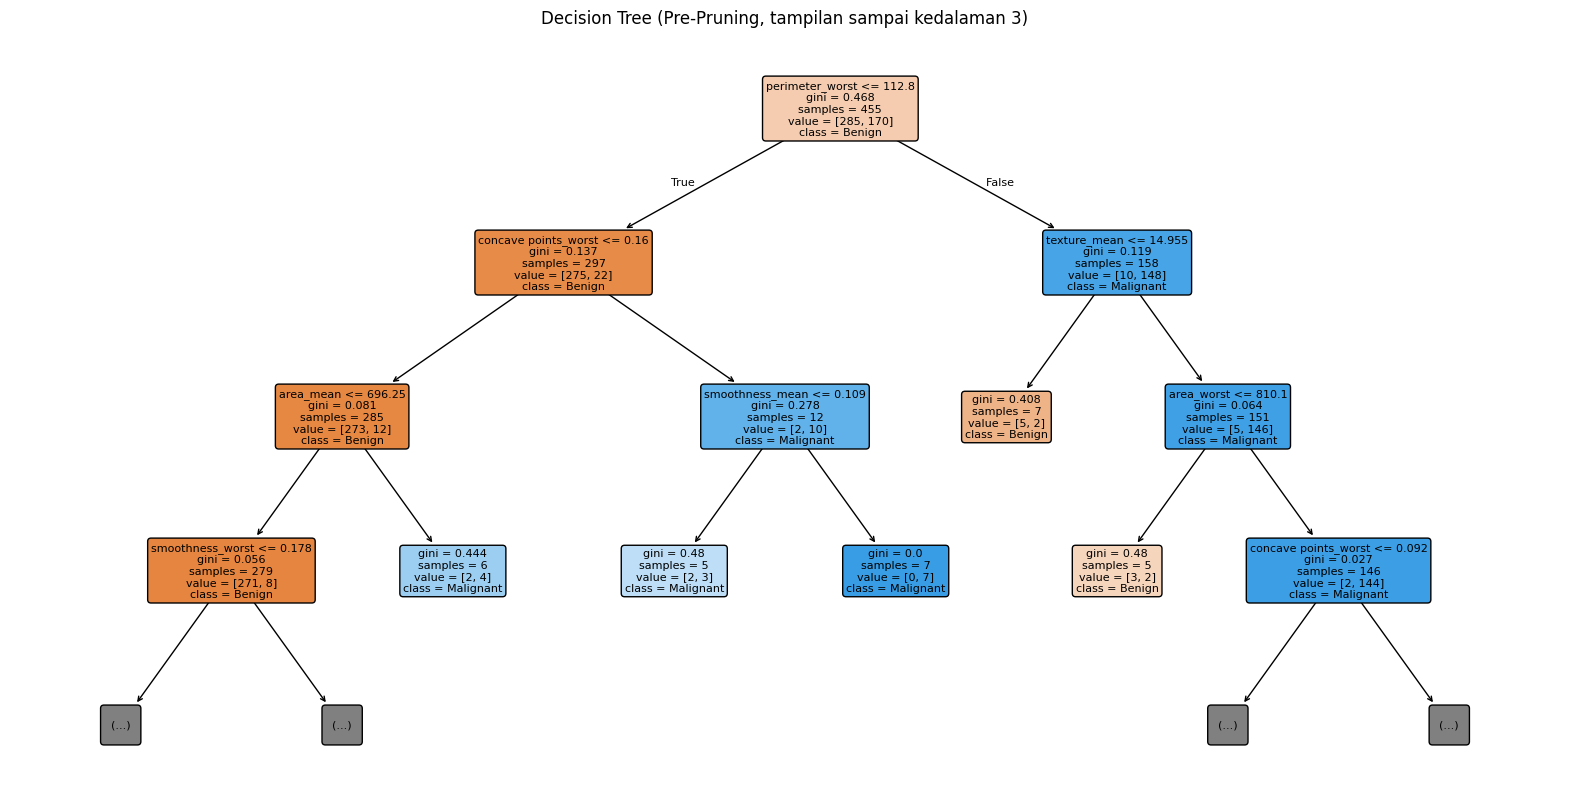

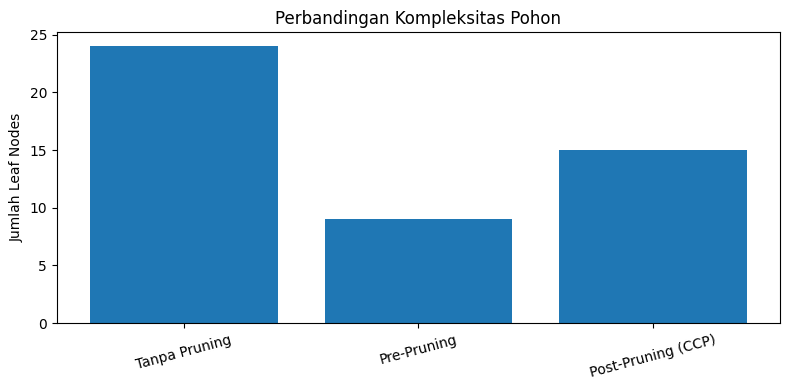

In [6]:
plt.figure(figsize=(20, 10))
plot_tree(
    tree_pre,
    feature_names=X.columns,
    class_names=["Benign", "Malignant"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree (Pre-Pruning, tampilan sampai kedalaman 3)")
plt.show()

# Perbandingan ukuran pohon
nama_model = [nama for nama, _ in model_list]
jumlah_daun = [model.get_n_leaves() for _, model in model_list]
plt.figure(figsize=(8, 4))
plt.bar(nama_model, jumlah_daun)
plt.ylabel("Jumlah Leaf Nodes")
plt.title("Perbandingan Kompleksitas Pohon")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 5.11.1 — Interpretasi Praktikum Utama

- **Tanpa pruning:** pohon tumbuh tanpa pembatasan kompleksitas. Akurasi training dapat sangat tinggi, tetapi selisih akurasi training dan testing yang besar mengindikasikan overfitting.
- **Pre-pruning:** membatasi pertumbuhan pohon sejak awal, misalnya dengan `max_depth` dan `min_samples_leaf`.
- **Post-pruning (CCP):** membangun pohon terlebih dahulu, kemudian memangkas cabang berdasarkan nilai `ccp_alpha`.
- Strategi yang baik tidak hanya mengejar akurasi training, tetapi juga akurasi testing yang baik dengan gap yang tidak terlalu besar.

## Latihan Praktikum 1 — Eksperimen Parameter Pre-Pruning

**Tujuan:** mengamati pengaruh kombinasi `max_depth` dan `min_samples_leaf` terhadap performa Decision Tree. Sesuai praktik yang lebih aman, parameter dibandingkan menggunakan validation set; test set tetap digunakan hanya untuk evaluasi final.

In [7]:
# Buat validation set dari training data
X_tr, X_val_pre, y_tr, y_val_pre = train_test_split(
    X_train, y_train, test_size=0.2, random_state=21, stratify=y_train
)

hasil_pre = []
for depth in [2, 4, 6, None]:
    for min_leaf in [1, 5, 10]:
        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=min_leaf,
            random_state=42
        )
        model.fit(X_tr, y_tr)

        pred_val = model.predict(X_val_pre)
        hasil_pre.append({
            "max_depth": str(depth),
            "min_samples_leaf": min_leaf,
            "Akurasi Train": accuracy_score(y_tr, model.predict(X_tr)),
            "Akurasi Validasi": accuracy_score(y_val_pre, pred_val),
            "F1 Validasi": __import__("sklearn.metrics").metrics.f1_score(
                y_val_pre, pred_val, zero_division=0
            ),
            "Jumlah Daun": model.get_n_leaves()
        })

tabel_pre = pd.DataFrame(hasil_pre).sort_values(
    by="Akurasi Validasi", ascending=False
)
display(tabel_pre.round(3))

kombinasi_terbaik = tabel_pre.iloc[0]
print("Kombinasi terbaik berdasarkan akurasi validasi:")
print(kombinasi_terbaik)

,max_depth,min_samples_leaf,Akurasi Train,Akurasi Validasi,F1 Validasi,Jumlah Daun
9,None,1,1.000,0.923,0.899,17
3,4,1,0.986,0.912,0.886,11
1,2,5,0.964,0.901,0.873,4
0,2,1,0.967,0.901,0.873,4
2,2,10,0.964,0.901,0.873,4
4,4,5,0.964,0.901,0.873,8
6,6,1,0.995,0.901,0.873,14
5,4,10,0.964,0.901,0.873,6
7,6,5,0.964,0.901,0.873,10
8,6,10,0.964,0.901,0.873,7


Kombinasi terbaik berdasarkan akurasi validasi:
max_depth               None
min_samples_leaf           1
Akurasi Train            1.0
Akurasi Validasi    0.923077
F1 Validasi         0.898551
Jumlah Daun               17
Name: 9, dtype: object


### Interpretasi Latihan 1

`max_depth` membatasi kedalaman maksimum pohon, sedangkan `min_samples_leaf` menentukan jumlah minimum sampel yang harus ada pada setiap daun. Nilai depth yang terlalu besar dan leaf yang terlalu kecil dapat membuat pohon kompleks dan berisiko overfitting. Pilih kombinasi berdasarkan akurasi validasi, kemudian uji sekali pada test set.

In [8]:
# Evaluasi final kombinasi pre-pruning terbaik pada test set
depth_best = None if kombinasi_terbaik["max_depth"] == "None" else int(kombinasi_terbaik["max_depth"])
leaf_best = int(kombinasi_terbaik["min_samples_leaf"])

tree_pre_best = DecisionTreeClassifier(
    max_depth=depth_best,
    min_samples_leaf=leaf_best,
    random_state=42
)
tree_pre_best.fit(X_train, y_train)
pred_pre_best_test = tree_pre_best.predict(X_test)

print("Parameter terbaik:", {
    "max_depth": depth_best,
    "min_samples_leaf": leaf_best
})
print("Akurasi testing:", round(accuracy_score(y_test, pred_pre_best_test), 3))
print(classification_report(
    y_test, pred_pre_best_test,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

Parameter terbaik: {'max_depth': None, 'min_samples_leaf': 1}
Akurasi testing: 0.93
              precision    recall  f1-score   support

      Benign       0.94      0.94      0.94        72
   Malignant       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



## Latihan Praktikum 2 — Cost Complexity Pruning Path

**Tujuan:** memilih `ccp_alpha` optimal berdasarkan akurasi validasi. Alpha kecil menghasilkan pohon yang lebih kompleks; alpha besar memangkas lebih banyak cabang. Pemilihan alpha menggunakan validation set, bukan test set.

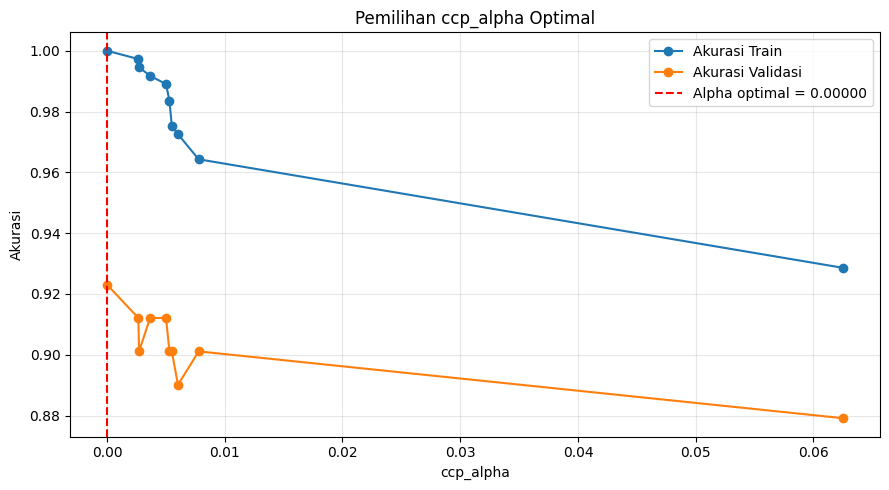

ccp_alpha optimal: 0.0
Akurasi validasi terbaik: 0.923
Jumlah leaf pada alpha optimal: 17


In [9]:
# Bangun path CCP dari data training
tree_for_path = DecisionTreeClassifier(random_state=42)
tree_for_path.fit(X_tr, y_tr)

path_latihan = tree_for_path.cost_complexity_pruning_path(X_tr, y_tr)
alphas_latihan = np.unique(path_latihan.ccp_alphas)
if len(alphas_latihan) > 1:
    alphas_latihan = alphas_latihan[:-1]

akurasi_train_alpha = []
akurasi_val_alpha = []
jumlah_leaf_alpha = []

for alpha in alphas_latihan:
    model = DecisionTreeClassifier(
        random_state=42, ccp_alpha=float(alpha)
    )
    model.fit(X_tr, y_tr)
    akurasi_train_alpha.append(accuracy_score(y_tr, model.predict(X_tr)))
    akurasi_val_alpha.append(accuracy_score(y_val_pre, model.predict(X_val_pre)))
    jumlah_leaf_alpha.append(model.get_n_leaves())

idx_opt = int(np.argmax(akurasi_val_alpha))
alpha_optimal = float(alphas_latihan[idx_opt])

plt.figure(figsize=(9, 5))
plt.plot(alphas_latihan, akurasi_train_alpha, marker="o", label="Akurasi Train")
plt.plot(alphas_latihan, akurasi_val_alpha, marker="o", label="Akurasi Validasi")
plt.axvline(alpha_optimal, color="red", linestyle="--",
            label=f"Alpha optimal = {alpha_optimal:.5f}")
plt.xlabel("ccp_alpha")
plt.ylabel("Akurasi")
plt.title("Pemilihan ccp_alpha Optimal")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("ccp_alpha optimal:", alpha_optimal)
print("Akurasi validasi terbaik:", round(akurasi_val_alpha[idx_opt], 3))
print("Jumlah leaf pada alpha optimal:", jumlah_leaf_alpha[idx_opt])

In [10]:
# Latih ulang model CCP terbaik pada seluruh data training, lalu evaluasi test
tree_ccp_best = DecisionTreeClassifier(
    random_state=42, ccp_alpha=alpha_optimal
)
tree_ccp_best.fit(X_train, y_train)
pred_ccp_best = tree_ccp_best.predict(X_test)

print("Akurasi testing CCP:", round(accuracy_score(y_test, pred_ccp_best), 3))
print("Jumlah leaf:", tree_ccp_best.get_n_leaves())
print("Kedalaman pohon:", tree_ccp_best.get_depth())
print(classification_report(
    y_test, pred_ccp_best,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

Akurasi testing CCP: 0.93
Jumlah leaf: 24
Kedalaman pohon: 8
              precision    recall  f1-score   support

      Benign       0.94      0.94      0.94        72
   Malignant       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



### Interpretasi Latihan 2

Grafik memperlihatkan perubahan akurasi training dan validasi ketika `ccp_alpha` bertambah. Alpha optimal dipilih pada titik dengan akurasi validasi tertinggi. Jika alpha terlalu besar, pohon dapat terlalu sederhana (underfitting); jika terlalu kecil, pohon dapat terlalu kompleks (overfitting). Hasil final kemudian diukur pada test set.

## Kesimpulan

1. Decision Tree tanpa pruning berpotensi memiliki akurasi training tinggi tetapi mengalami overfitting.
2. Pre-pruning mengendalikan kompleksitas sejak proses pembentukan pohon.
3. Cost Complexity Pruning memangkas pohon setelah terbentuk berdasarkan parameter `ccp_alpha`.
4. `max_depth`, `min_samples_leaf`, dan `ccp_alpha` perlu dipilih menggunakan data validasi.
5. Evaluasi akhir dilakukan pada test set yang tidak dipakai untuk memilih parameter.

**Penting:** dataset ini berisi data diagnosis tumor payudara untuk keperluan pembelajaran machine learning. Model praktikum bukan alat diagnosis medis dan tidak boleh digunakan untuk mengambil keputusan klinis.